# Build a tract-based health-need index

This notebook uses the CDC PLACES **2024 release**, a model-based set of tract estimates with underlying BRFSS, Census, and ACS reference years before 2024. The index is an exploratory summary of 12 adverse health prevalence measures, not a clinical risk score. PC1 is oriented so higher values point toward higher prevalence on average. County scores are weighted by tract adult population because the input prevalence measures describe adults.

In [1]:
import sys

In [2]:
print(sys.executable)

/Library/Frameworks/Python.framework/Versions/3.13/bin/python3


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [4]:
df = pd.read_csv("../data/raw/export.csv")

In [5]:
df.head()

,StateAbbr,StateDesc,CountyName,CountyFIPS,TractFIPS,TotalPopulation,TotalPop18plus,ACCESS2_CrudePrev,ACCESS2_Crude95CI,ARTHRITIS_CrudePrev,...,FOODINSECU_Crude95CI,HOUSINSECU_CrudePrev,HOUSINSECU_Crude95CI,SHUTUTILITY_CrudePrev,SHUTUTILITY_Crude95CI,LACKTRPT_CrudePrev,LACKTRPT_Crude95CI,EMOTIONSPT_CrudePrev,EMOTIONSPT_Crude95CI,Geolocation
0,AL,Alabama,Autauga,1001,1001020100,1775,"1,370",11.2,"( 8.7, 14.2)",35.2,...,"(14.9, 18.6)",14.2,"(12.5, 16.0)",9.3,"( 8.1, 10.6)",9.7,"( 8.8, 10.7)",25.9,"(22.4, 29.7)",POINT (-86.4915648 32.4819731)
1,AL,Alabama,Autauga,1001,1001020200,2055,"1,584",10.7,"( 8.6, 12.9)",32.3,...,"(19.1, 23.5)",19.1,"(17.1, 21.3)",12.1,"(10.7, 13.8)",11.4,"(10.4, 12.6)",30.7,"(27.0, 34.9)",POINT (-86.4724678 32.475758)
2,AL,Alabama,Autauga,1001,1001020300,3216,"2,485",10.9,"( 8.7, 13.5)",35.7,...,"(15.2, 18.9)",15.0,"(13.3, 16.8)",9.8,"( 8.7, 11.2)",9.8,"( 9.0, 10.9)",25.9,"(22.4, 29.6)",POINT (-86.4597033 32.4740243)
3,AL,Alabama,Autauga,1001,1001020400,4246,"3,344",8.4,"( 6.5, 10.8)",37.0,...,"(11.1, 14.0)",10.7,"( 9.5, 12.1)",6.9,"( 6.0, 7.8)",7.6,"( 6.9, 8.4)",24.7,"(21.4, 28.5)",POINT (-86.4448353 32.4710304)
4,AL,Alabama,Autauga,1001,1001020501,4322,"3,369",7.9,"( 6.1, 10.3)",32.3,...,"( 8.9, 11.4)",9.6,"( 8.5, 10.9)",6.2,"( 5.4, 7.1)",6.5,"( 5.9, 7.3)",23.1,"(19.9, 26.6)",POINT (-86.4225578 32.4478607)


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83522 entries, 0 to 83521
Data columns (total 88 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   StateAbbr               83522 non-null  object 
 1   StateDesc               83522 non-null  object 
 2   CountyName              83522 non-null  object 
 3   CountyFIPS              83522 non-null  int64  
 4   TractFIPS               83522 non-null  int64  
 5   TotalPopulation         83522 non-null  int64  
 6   TotalPop18plus          83522 non-null  object 
 7   ACCESS2_CrudePrev       83522 non-null  float64
 8   ACCESS2_Crude95CI       83522 non-null  object 
 9   ARTHRITIS_CrudePrev     83522 non-null  float64
 10  ARTHRITIS_Crude95CI     83522 non-null  object 
 11  BINGE_CrudePrev         83522 non-null  float64
 12  BINGE_Crude95CI         83522 non-null  object 
 13  BPHIGH_CrudePrev        78445 non-null  float64
 14  BPHIGH_Crude95CI        78445 non-null

In [7]:
df.columns.tolist()

['StateAbbr',
 'StateDesc',
 'CountyName',
 'CountyFIPS',
 'TractFIPS',
 'TotalPopulation',
 'TotalPop18plus',
 'ACCESS2_CrudePrev',
 'ACCESS2_Crude95CI',
 'ARTHRITIS_CrudePrev',
 'ARTHRITIS_Crude95CI',
 'BINGE_CrudePrev',
 'BINGE_Crude95CI',
 'BPHIGH_CrudePrev',
 'BPHIGH_Crude95CI',
 'BPMED_CrudePrev',
 'BPMED_Crude95CI',
 'CANCER_CrudePrev',
 'CANCER_Crude95CI',
 'CASTHMA_CrudePrev',
 'CASTHMA_Crude95CI',
 'CHD_CrudePrev',
 'CHD_Crude95CI',
 'CHECKUP_CrudePrev',
 'CHECKUP_Crude95CI',
 'CHOLSCREEN_CrudePrev',
 'CHOLSCREEN_Crude95CI',
 'COLON_SCREEN_CrudePrev',
 'COLON_SCREEN_Crude95CI',
 'COPD_CrudePrev',
 'COPD_Crude95CI',
 'CSMOKING_CrudePrev',
 'CSMOKING_Crude95CI',
 'DENTAL_CrudePrev',
 'DENTAL_Crude95CI',
 'DEPRESSION_CrudePrev',
 'DEPRESSION_Crude95CI',
 'DIABETES_CrudePrev',
 'DIABETES_Crude95CI',
 'GHLTH_CrudePrev',
 'GHLTH_Crude95CI',
 'HIGHCHOL_CrudePrev',
 'HIGHCHOL_Crude95CI',
 'LPA_CrudePrev',
 'LPA_Crude95CI',
 'MAMMOUSE_CrudePrev',
 'MAMMOUSE_Crude95CI',
 'MHLTH_CrudePr

In [8]:
keep_cols = [
    # Geography / population
    "StateAbbr",
    "StateDesc",
    "CountyName",
    "CountyFIPS",
    "TractFIPS",
    "TotalPopulation",
    "TotalPop18plus",
    "Geolocation",

    # Chronic disease / health need
    "DIABETES_CrudePrev",
    "COPD_CrudePrev",
    "CHD_CrudePrev",
    "STROKE_CrudePrev",
    "BPHIGH_CrudePrev",
    "HIGHCHOL_CrudePrev",
    "CASTHMA_CrudePrev",
    "ARTHRITIS_CrudePrev",
    "GHLTH_CrudePrev",
    "PHLTH_CrudePrev",
    "DISABILITY_CrudePrev",

    # Primary care / preventive care outcomes
    "CHECKUP_CrudePrev",
    "CHOLSCREEN_CrudePrev",
    "BPMED_CrudePrev",

    # Healthcare access barriers
    "ACCESS2_CrudePrev",
    "LACKTRPT_CrudePrev",

    # Major behavioral risk factors
    "CSMOKING_CrudePrev",
    "OBESITY_CrudePrev",
    "LPA_CrudePrev",
    "BINGE_CrudePrev",

    # Mental / social factors
    "DEPRESSION_CrudePrev",
    "MHLTH_CrudePrev",
    "ISOLATION_CrudePrev",
    "EMOTIONSPT_CrudePrev",

    # Economic / material hardship
    "FOODSTAMP_CrudePrev",
    "FOODINSECU_CrudePrev",
    "HOUSINSECU_CrudePrev",
    "SHUTUTILITY_CrudePrev"
]

df_small = df[keep_cols].copy()
df_small["TotalPop18plus"] = pd.to_numeric(
    df_small["TotalPop18plus"].astype(str).str.replace(",", "", regex=False),
    errors="coerce",
)
if df_small["TotalPop18plus"].isna().any() or df_small["TotalPop18plus"].le(0).any():
    raise ValueError("Every tract needs a positive, numeric adult population for county aggregation.")

In [9]:
df_small.shape

(83522, 36)

In [10]:
df_small.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83522 entries, 0 to 83521
Data columns (total 36 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   StateAbbr              83522 non-null  object 
 1   StateDesc              83522 non-null  object 
 2   CountyName             83522 non-null  object 
 3   CountyFIPS             83522 non-null  int64  
 4   TractFIPS              83522 non-null  int64  
 5   TotalPopulation        83522 non-null  int64  
 6   TotalPop18plus         83522 non-null  int64  
 7   Geolocation            83522 non-null  object 
 8   DIABETES_CrudePrev     83522 non-null  float64
 9   COPD_CrudePrev         83522 non-null  float64
 10  CHD_CrudePrev          83522 non-null  float64
 11  STROKE_CrudePrev       83522 non-null  float64
 12  BPHIGH_CrudePrev       78445 non-null  float64
 13  HIGHCHOL_CrudePrev     78445 non-null  float64
 14  CASTHMA_CrudePrev      83522 non-null  float64
 15  AR

In [11]:
df_small.isna().sum().sort_values(ascending=False)

SHUTUTILITY_CrudePrev    19635
HOUSINSECU_CrudePrev     19635
FOODINSECU_CrudePrev     19635
FOODSTAMP_CrudePrev      19635
EMOTIONSPT_CrudePrev     19635
ISOLATION_CrudePrev      19635
LACKTRPT_CrudePrev       19635
BPHIGH_CrudePrev          5077
BPMED_CrudePrev           5077
HIGHCHOL_CrudePrev        5077
CHOLSCREEN_CrudePrev      5077
OBESITY_CrudePrev            0
LPA_CrudePrev                0
CHECKUP_CrudePrev            0
CSMOKING_CrudePrev           0
DEPRESSION_CrudePrev         0
ACCESS2_CrudePrev            0
MHLTH_CrudePrev              0
BINGE_CrudePrev              0
StateAbbr                    0
StateDesc                    0
PHLTH_CrudePrev              0
GHLTH_CrudePrev              0
ARTHRITIS_CrudePrev          0
CASTHMA_CrudePrev            0
STROKE_CrudePrev             0
CHD_CrudePrev                0
COPD_CrudePrev               0
DIABETES_CrudePrev           0
Geolocation                  0
TotalPop18plus               0
TotalPopulation              0
TractFIP

In [12]:
df_small.loc[
    df_small["FOODINSECU_CrudePrev"].isna(),
    "StateAbbr"
].value_counts()

StateAbbr
NY    5289
PA    3408
IL    3258
VA    2166
CO    1437
LA    1367
OR     993
AR     821
HI     426
SD     242
ND     228
Name: count, dtype: int64

In [13]:
df_small.loc[
    df_small["BPHIGH_CrudePrev"].isna(),
    "StateAbbr"
].value_counts()

StateAbbr
FL    5077
Name: count, dtype: int64

In [14]:
social_cols = [
    "FOODSTAMP_CrudePrev",
    "FOODINSECU_CrudePrev",
    "HOUSINSECU_CrudePrev",
    "SHUTUTILITY_CrudePrev",
    "LACKTRPT_CrudePrev",
    "ISOLATION_CrudePrev",
    "EMOTIONSPT_CrudePrev"
]

df_small[social_cols].isna().sum()

FOODSTAMP_CrudePrev      19635
FOODINSECU_CrudePrev     19635
HOUSINSECU_CrudePrev     19635
SHUTUTILITY_CrudePrev    19635
LACKTRPT_CrudePrev       19635
ISOLATION_CrudePrev      19635
EMOTIONSPT_CrudePrev     19635
dtype: int64

In [15]:
core_need_cols = [
    "DIABETES_CrudePrev",
    "COPD_CrudePrev",
    "CHD_CrudePrev",
    "STROKE_CrudePrev",
    "GHLTH_CrudePrev",
    "PHLTH_CrudePrev",
    "DISABILITY_CrudePrev",
    "OBESITY_CrudePrev",
    "LPA_CrudePrev",
    "CSMOKING_CrudePrev",
    "DEPRESSION_CrudePrev",
    "MHLTH_CrudePrev"
]

outcome_cols = [
    "CHECKUP_CrudePrev"
]

In [16]:
context_cols = [
    "FOODSTAMP_CrudePrev",
    "FOODINSECU_CrudePrev",
    "HOUSINSECU_CrudePrev",
    "SHUTUTILITY_CrudePrev",
    "LACKTRPT_CrudePrev",
    "ISOLATION_CrudePrev",
    "EMOTIONSPT_CrudePrev"
]

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [18]:
X_need = df_small[core_need_cols].copy()

In [19]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_need)

In [20]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)
if pca.components_[0].sum() < 0:
    pca.components_[0] *= -1
    X_pca[:, 0] *= -1

In [21]:
pca.explained_variance_ratio_

array([0.73103945, 0.1264315 , 0.06987943, 0.03017194, 0.01483633,
       0.00869886, 0.00705421, 0.00443181, 0.0028104 , 0.00219919,
       0.00151176, 0.00093514])

In [22]:
pca.explained_variance_ratio_.cumsum()

array([0.73103945, 0.85747095, 0.92735037, 0.95752231, 0.97235864,
       0.98105751, 0.98811171, 0.99254352, 0.99535392, 0.9975531 ,
       0.99906486, 1.        ])

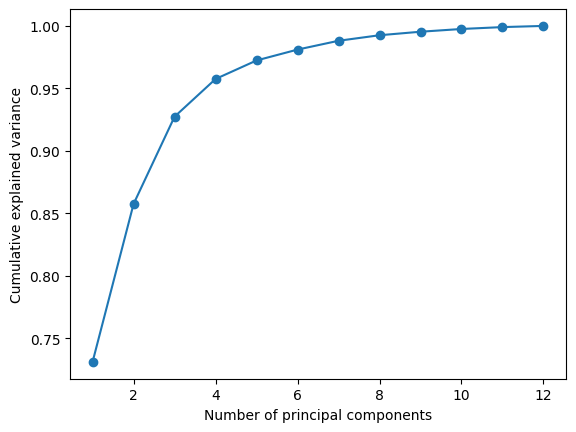

In [23]:
import matplotlib.pyplot as plt

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    pca.explained_variance_ratio_.cumsum(),
    marker="o"
)

plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.show()

In [24]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=core_need_cols,
    columns=[f"PC{i+1}" for i in range(len(core_need_cols))]
)

loadings[["PC1", "PC2"]].sort_values("PC1", ascending=False)

,PC1,PC2
PHLTH_CrudePrev,0.327907,-0.005225
DISABILITY_CrudePrev,0.326871,0.055024
GHLTH_CrudePrev,0.315994,0.036617
LPA_CrudePrev,0.314606,-0.000073
CSMOKING_CrudePrev,0.311005,0.158841
COPD_CrudePrev,0.305405,-0.124805
STROKE_CrudePrev,0.302453,-0.296944
DIABETES_CrudePrev,0.299397,-0.285403
OBESITY_CrudePrev,0.281421,0.125868
CHD_CrudePrev,0.246462,-0.407890


In [25]:
df_small["NeedScore"] = X_pca[:, 0]

In [26]:
df_small["NeedScore"].describe()

count    8.352200e+04
mean     1.306714e-16
std      2.961854e+00
min     -8.037040e+00
25%     -2.138514e+00
50%     -3.070372e-01
75%      1.782804e+00
max      1.761404e+01
Name: NeedScore, dtype: float64

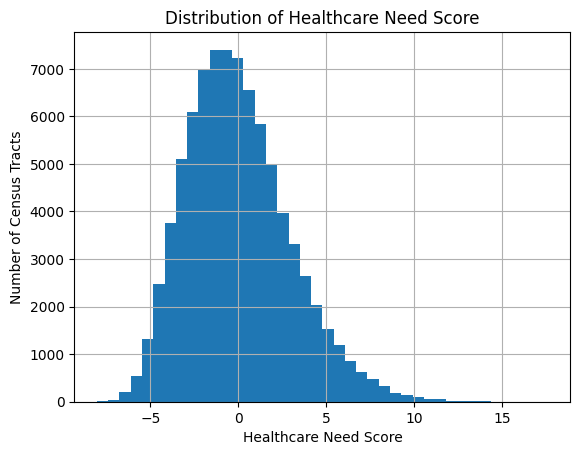

In [27]:
df_small["NeedScore"].hist(bins=40)
plt.xlabel("Healthcare Need Score")
plt.ylabel("Number of Census Tracts")
plt.title("Distribution of Healthcare Need Score")
plt.show()

In [28]:
df_small[
    ["StateAbbr", "CountyName", "TractFIPS", "NeedScore"]
].sort_values("NeedScore", ascending=False).head(10)

,StateAbbr,CountyName,TractFIPS,NeedScore
52830,NY,Queens,36081042600,17.614039
40423,MI,Wayne,26163983400,17.057396
61284,OK,Oklahoma,40109980009,16.503982
57821,OH,Cuyahoga,39035112100,16.088381
71868,TX,El Paso,48141001800,15.975135
32009,KY,Jefferson,21111005901,15.088118
71870,TX,El Paso,48141002000,14.893410
11420,CA,San Francisco,6075980501,14.656270
32866,LA,Caddo,22017023802,14.479415
49166,NM,Socorro,35053940000,14.363060


In [29]:
df_small[
    ["StateAbbr", "CountyName", "TractFIPS", "NeedScore"]
].sort_values("NeedScore").head(10)

,StateAbbr,CountyName,TractFIPS,NeedScore
47386,NJ,Hudson,34017007702,-8.037040
12121,CA,Santa Clara,6085505012,-7.810673
12105,CA,Santa Clara,6085504509,-7.735513
47385,NJ,Hudson,34017007701,-7.660652
79971,WA,King,53033006701,-7.633314
47383,NJ,Hudson,34017007601,-7.628715
52556,NY,Queens,36081001902,-7.462055
47384,NJ,Hudson,34017007602,-7.382371
51722,NY,Nassau,36059980100,-7.356620
47380,NJ,Hudson,34017007300,-7.337737


In [30]:
compare_cols = [
    "StateAbbr",
    "CountyName",
    "TractFIPS",
    "NeedScore",
    "DIABETES_CrudePrev",
    "COPD_CrudePrev",
    "CHD_CrudePrev",
    "STROKE_CrudePrev",
    "GHLTH_CrudePrev",
    "PHLTH_CrudePrev",
    "DISABILITY_CrudePrev",
    "OBESITY_CrudePrev",
    "LPA_CrudePrev",
    "CSMOKING_CrudePrev",
    "DEPRESSION_CrudePrev",
    "MHLTH_CrudePrev"
]

In [31]:
df_small[compare_cols].sort_values("NeedScore", ascending=False).head(5)

,StateAbbr,CountyName,TractFIPS,NeedScore,DIABETES_CrudePrev,COPD_CrudePrev,CHD_CrudePrev,STROKE_CrudePrev,GHLTH_CrudePrev,PHLTH_CrudePrev,DISABILITY_CrudePrev,OBESITY_CrudePrev,LPA_CrudePrev,CSMOKING_CrudePrev,DEPRESSION_CrudePrev,MHLTH_CrudePrev
52830,NY,Queens,36081042600,17.614039,44.7,25.2,37.1,22.6,53.9,32.1,69.5,39.2,59.6,18.3,9.9,11.5
40423,MI,Wayne,26163983400,17.057396,26.8,34.9,28.2,18.6,52.9,35.5,72.1,35.2,55.0,21.1,28.2,24.9
61284,OK,Oklahoma,40109980009,16.503982,29.9,24.9,16.9,11.7,59.0,33.8,68.4,60.5,60.4,47.2,30.0,29.8
57821,OH,Cuyahoga,39035112100,16.088381,37.8,26.3,21.2,16.8,55.4,31.1,63.2,55.3,55.0,32.1,20.1,21.4
71868,TX,El Paso,48141001800,15.975135,37.5,19.7,19.6,11.9,67.3,36.4,69.2,51.2,64.5,32.8,24.6,25.0


In [32]:
df_small[compare_cols].sort_values("NeedScore").head(5)

,StateAbbr,CountyName,TractFIPS,NeedScore,DIABETES_CrudePrev,COPD_CrudePrev,CHD_CrudePrev,STROKE_CrudePrev,GHLTH_CrudePrev,PHLTH_CrudePrev,DISABILITY_CrudePrev,OBESITY_CrudePrev,LPA_CrudePrev,CSMOKING_CrudePrev,DEPRESSION_CrudePrev,MHLTH_CrudePrev
47386,NJ,Hudson,34017007702,-8.037040,2.5,0.8,1.0,0.6,5.4,4.1,9.6,14.4,12.3,4.0,11.6,10.4
12121,CA,Santa Clara,6085505012,-7.810673,3.3,0.9,1.2,0.7,5.6,4.4,10.6,14.9,9.4,3.9,14.9,10.7
12105,CA,Santa Clara,6085504509,-7.735513,5.1,1.0,1.5,0.9,6.4,4.6,10.9,12.8,11.3,3.7,11.8,9.3
47385,NJ,Hudson,34017007701,-7.660652,3.6,1.1,1.4,0.8,6.2,4.7,10.2,15.3,13.7,4.5,10.9,9.8
79971,WA,King,53033006701,-7.633314,2.4,1.0,1.2,0.7,5.3,4.5,10.8,15.8,7.2,3.5,20.5,12.4


In [33]:
df_small["adult_weighted_need"] = (
    df_small["NeedScore"] * df_small["TotalPop18plus"]
)
df_small["total_weighted_need"] = (
    df_small["NeedScore"] * df_small["TotalPopulation"]
)

In [34]:
county_need = (
    df_small
    .groupby(
        ["StateAbbr", "CountyName", "CountyFIPS"],
        as_index=False
    )
    .agg(
        adult_weighted_need_sum=("adult_weighted_need", "sum"),
        total_weighted_need_sum=("total_weighted_need", "sum"),
        adult_population=("TotalPop18plus", "sum"),
        total_population=("TotalPopulation", "sum"),
    )
)

In [35]:
county_need["NeedScore"] = (
    county_need["adult_weighted_need_sum"] /
    county_need["adult_population"]
)
county_need["NeedScoreTotalPopulationWeighted"] = (
    county_need["total_weighted_need_sum"] /
    county_need["total_population"]
)
print(
    "Adult- versus total-population-weighted county score correlation: "
    f"{county_need[['NeedScore', 'NeedScoreTotalPopulationWeighted']].corr().iloc[0, 1]:.5f}"
)
print(
    "Median absolute difference in county scores: "
    f"{(county_need['NeedScore'] - county_need['NeedScoreTotalPopulationWeighted']).abs().median():.4f}"
)

Adult- versus total-population-weighted county score correlation: 0.99982
Median absolute difference in county scores: 0.0115


In [36]:
county_need.shape

(3143, 9)

In [37]:
county_need.head()

,StateAbbr,CountyName,CountyFIPS,adult_weighted_need_sum,total_weighted_need_sum,adult_population,total_population,NeedScore,NeedScoreTotalPopulationWeighted
0,AK,Aleutians East,2013,1257.731500,1378.667221,3120,3420,0.403119,0.403119
1,AK,Aleutians West,2016,-8201.376639,-9190.175458,4579,5232,-1.791085,-1.756532
2,AK,Anchorage,2020,-406342.345104,-529644.509057,222910,291242,-1.822899,-1.818572
3,AK,Bethel,2050,54186.932529,86591.752799,12130,18666,4.467183,4.639010
4,AK,Bristol Bay,2060,-205.658450,-263.792906,658,844,-0.312551,-0.312551


In [38]:
county_need.to_csv(
    "../data/processed/county_need_2024.csv",
    index=False
)